# Взвешенная цепочка на Python

## Подготовка

Выполните все ячейки сверху вниз. Проверенная версия пакета: **0.9.0**.

In [1]:
from importlib.metadata import version, PackageNotFoundError
import importlib.util
import subprocess
import sys

# Install only when the required package version is missing.
try:
    installed = version("polyform_algebra")
except PackageNotFoundError:
    installed = None
if installed != "0.9.0":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                          "https://github.com/magin67/polyform_algebra/archive/refs/tags/v0.9.0.zip"])
if importlib.util.find_spec("matplotlib") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])


In [2]:
import polyform_algebra
assert polyform_algebra.get_version() == "0.9.0"
print("polyform_algebra", polyform_algebra.get_version())

polyform_algebra 0.9.0


Пример воспроизводит цепочку $1-2-3$ с проводимостями $c_{12}=1$, $c_{23}=2$ из заметок [Лапласиан - граф, электрическая сеть и квадратичная форма](https://magin67.github.io/pmg-notes/ru/%D0%BD%D0%B0%D1%87%D0%B0%D0%BB%D0%BE-%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D1%8B-%D0%B8-%D0%BE%D1%81%D0%BD%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D1%8F/%D0%B2%D0%B2%D0%B5%D0%B4%D0%B5%D0%BD%D0%B8%D0%B5/%D0%BB%D0%B0%D0%BF%D0%BB%D0%B0%D1%81%D0%B8%D0%B0%D0%BD---%D0%B3%D1%80%D0%B0%D1%84,-%D1%8D%D0%BB%D0%B5%D0%BA%D1%82%D1%80%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B0%D1%8F-%D1%81%D0%B5%D1%82%D1%8C-%D0%B8-%D0%BA%D0%B2%D0%B0%D0%B4%D1%80%D0%B0%D1%82%D0%B8%D1%87%D0%BD%D0%B0%D1%8F-%D1%84%D0%BE%D1%80%D0%BC%D0%B0) и [Эффективное сопротивление и геометрия графа](https://magin67.github.io/pmg-notes/ru/%D0%BD%D0%B0%D1%87%D0%B0%D0%BB%D0%BE-%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D1%8B-%D0%B8-%D0%BE%D1%81%D0%BD%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D1%8F/%D0%B2%D0%B2%D0%B5%D0%B4%D0%B5%D0%BD%D0%B8%D0%B5/%D1%8D%D1%84%D1%84%D0%B5%D0%BA%D1%82%D0%B8%D0%B2%D0%BD%D0%BE%D0%B5-%D1%81%D0%BE%D0%BF%D1%80%D0%BE%D1%82%D0%B8%D0%B2%D0%BB%D0%B5%D0%BD%D0%B8%D0%B5-%D0%B8-%D0%B3%D0%B5%D0%BE%D0%BC%D0%B5%D1%82%D1%80%D0%B8%D1%8F-%D0%B3%D1%80%D0%B0%D1%84%D0%B0#%D0%BF%D1%80%D0%B8%D0%BC%D0%B5%D1%80-%D1%86%D0%B5%D0%BF%D0%BE%D1%87%D0%BA%D0%B0-%D0%B8%D0%B7-%D1%82%D1%80%D1%91%D1%85-%D0%B2%D0%B5%D1%80%D1%88%D0%B8%D0%BD). Сопротивления вычисляются через метрическую полиформу; уравнения токов дают независимую проверку.



Пример проверен с `polyform_algebra 0.9.0`. Подготовка окружения: [Установка библиотеки и запуск примеров](https://magin67.github.io/pmg-notes/ru/pythonexamples/%D1%83%D1%81%D1%82%D0%B0%D0%BD%D0%BE%D0%B2%D0%BA%D0%B0-%D0%B1%D0%B8%D0%B1%D0%BB%D0%B8%D0%BE%D1%82%D0%B5%D0%BA%D0%B8-%D0%B8-%D0%B7%D0%B0%D0%BF%D1%83%D1%81%D0%BA-%D0%BF%D1%80%D0%B8%D0%BC%D0%B5%D1%80%D0%BE%D0%B2). Ячейки Python выполняются по порядку.

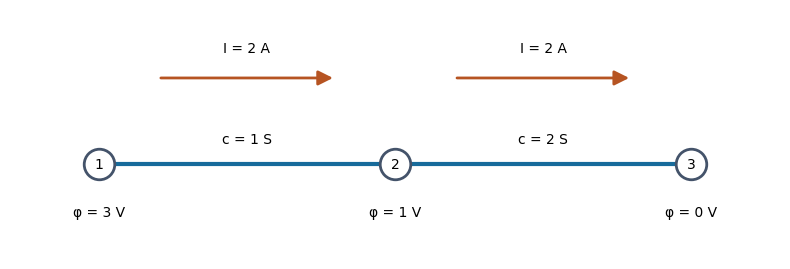

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot([0, 1, 2], [0, 0, 0], color="#176b9b", linewidth=3)
for x, label, voltage in [(0, "1", 3), (1, "2", 1), (2, "3", 0)]:
    ax.plot(x, 0, "o", markersize=22, color="white", markeredgecolor="#44536a", markeredgewidth=2)
    ax.text(x, 0, label, ha="center", va="center")
    ax.text(x, -.3, f"φ = {voltage} V", ha="center")
for x, conductance in [(0, 1), (1, 2)]:
    ax.text(x + .5, .12, f"c = {conductance} S", ha="center")
    ax.annotate("", (x + .8, .5), (x + .2, .5),
                arrowprops={"arrowstyle": "-|>", "mutation_scale": 22, "color": "#b65422", "lw": 2})
    ax.text(x + .5, .65, "I = 2 A", ha="center")
ax.set(xlim=(-.3, 2.3), ylim=(-.55, .9))
ax.axis("off")
plt.tight_layout()
plt.show()


## От графа к метрической полиформе

Вес ребра означает проводимость. Сопротивления рёбер равны обратным величинам: $1$ и $1/2$. Прямого ребра $13$ нет.

In [4]:
import networkx as nx
from polyform_algebra import Polyform, quForm

# Edge weights are conductances.
graph = nx.Graph()
graph.add_weighted_edges_from([(1, 2, 1), (2, 3, 2)])
laplacian, points = Polyform.from_networkx(graph, return_points="dict")
metric = laplacian.exp()

print("tau =", metric.potential(quForm.one()))
for i, j in [(1, 2), (2, 3), (1, 3)]:
    form = quForm([(points[i], points[j])])
    print(f"R{i}{j} =", metric.norm(form))

tau = 2.0
R12 = 1.0
R23 = 0.5
R13 = 1.5


Форма $f_{ij}=[a_j-a_i]^2$ задаёт квадратичную форму ребра. Нильпотентность рёберных форм даёт

$$
L=f_{12}+2f_{23},\qquad
M=\exp L=(e+f_{12})(e+2f_{23})
$$
В программе это экспонента в алгебре форм, а не матричная экспонента. Величина `potential(quForm.one())` даёт остовной коэффициент, а `norm(form)` - нормированную метрическую оценку.

| Величина | Результат | Объяснение |
|---|---:|---|
| $\tau$ | $2$ | Единственное остовное дерево имеет вес $1\cdot2$ |
| $R_{12}$ | $1$ | Сопротивление первого ребра |
| $R_{23}$ | $1/2$ | Сопротивление второго ребра |
| $R_{13}$ | $3/2$ | Сумма последовательных сопротивлений |

Наличие сопротивления $R_{13}$ не означает наличие ребра $13$. В резистивном евклидовом представлении это квадрат расстояния; само расстояние равно $\sqrt{3/2}$.

## Матрица, токи и мощность

Метод `to_matrix()` возвращает матрицу и соответствие точек индексам. В порядке вершин $1,2,3$:

$$
\mathbf L=
\begin{pmatrix}
1&-1&0\\
-1&3&-2\\
0&-2&2
\end{pmatrix}
$$
Воспроизведём опыт первой заметки: вводим 2 А в вершину 1, выводим 2 А через вершину 3 и выбираем $\varphi_3=0$.

In [5]:
import numpy as np

matrix, index = laplacian.to_matrix()
# Reorder rows and columns explicitly as vertices 1, 2, 3.
order = [index[points[label]] for label in (1, 2, 3)]
matrix = np.asarray(matrix[np.ix_(order, order)], dtype=float)
# Ground vertex 3 and inject 2 A at vertex 1.
current = np.array([2.0, 0.0, -2.0])
potential = np.append(np.linalg.solve(matrix[:2, :2], current[:2]), 0.0)
print("potentials =", potential)
print("power =", potential @ matrix @ potential)

potentials = [3. 1. 0.]
power = 6.0


Получаем

$$
\varphi=(3,1,0)^{\mathsf T},\qquad
I_{12}=I_{23}=2,\qquad
\mathcal Q=1(3-1)^2+2(1-0)^2=6
$$
Баланс мощности также даёт $\varphi^{\mathsf T}J=6$ и $I^2R_{13}=4\cdot3/2=6$. При проводимостях в сименсах потенциалы измеряются в вольтах, мощность - в ваттах. Матрица получена средствами пакета; NumPy решает уравнения токов. Ниже эта матрица сверяется с независимым эталоном, составленным непосредственно из проводимостей.

## Проверки

Три математических теста проверяют матрицу и сопротивления, остовной коэффициент и разложение экспоненты, уравнения токов и три способа вычисления мощности. Независимый эталон строит лапласиан явно, без преобразования полиформ: его минор даёт $\tau$, а три решения с единичным током проверяют все пары сопротивлений. Общие проверки примеров дополнительно проверяют запуск модуля и отсутствие вывода при импорте.

In [6]:
from math import isclose

reference = np.array([[1., -1., 0.], [-1., 3., -2.], [0., -2., 2.]])
assert np.allclose(matrix, reference)
assert np.allclose(reference @ potential, current)
assert np.allclose(potential, [3., 1., 0.])
assert isclose(float(metric.potential(quForm.one())), 2.)
assert isclose(float(metric.norm(quForm([(points[1], points[3])]))), 1.5)
assert isclose(float(potential @ reference @ potential), 6.)

## Попробуйте изменить

Измените проводимость второго ребра с 2 на 4. Получите $R_{13}=5/4$ и мощность 5 при прежнем токе 2 А.

Численные проверки относятся к этому примеру и не заменяют общего доказательства.